# 03. Classical machine learning on handcrafted features

Questions: *how do Decision Trees, logistic regression, k-NN, SVMs, Random Forests and XGBoost compare
on the same features, does preprocessing help them, and how much does data leakage matter?*

Protocol: one group-aware split (near-duplicates never cross it); hyperparameters chosen by stratified
group 5-fold cross-validation on the training split; each classifier's final feature set chosen by CV;
the test split used once per final model.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from idefect.config import load_config

cfg = load_config("configs/neu_baseline.yaml")
RES = Path(cfg.output.results_dir)
FIG = Path(cfg.output.figures_dir)


def show(path):
    # Display a saved figure at full resolution.
    display(Image(filename=str(path)))


## Full grid: feature set x classifier

In [2]:
df = pd.DataFrame(json.loads((RES / "classical" / "grid.json").read_text()))
cols = ["feature_set", "model", "feature_dim", "cv_macro_f1_mean", "cv_macro_f1_std", "val_macro_f1",
        "test_macro_f1", "test_roc_auc", "search_time_sec"]
df[cols].sort_values(["model", "cv_macro_f1_mean"], ascending=[True, False]).round(4)

,feature_set,model,feature_dim,cv_macro_f1_mean,cv_macro_f1_std,val_macro_f1,test_macro_f1,test_roc_auc,search_time_sec
18,lbp+glcm,decision_tree,102,0.8867,0.0461,0.8621,0.9216,0.9599,1.11
24,hog+lbp+glcm,decision_tree,1866,0.8675,0.0343,0.8556,0.8427,0.9504,22.09
12,glcm,decision_tree,48,0.8555,0.0415,0.8486,0.8906,0.9573,0.71
6,lbp,decision_tree,54,0.8196,0.0291,0.7598,0.7733,0.8654,17.94
0,hog,decision_tree,1764,0.5477,0.0432,0.4881,0.4880,0.7174,48.09
20,lbp+glcm,knn,102,0.9023,0.0345,0.8821,0.9401,0.9643,0.18
14,glcm,knn,48,0.8926,0.0420,0.8735,0.9094,0.9469,0.14
26,hog+lbp+glcm,knn,1866,0.8630,0.0266,0.8336,0.8462,0.9090,1.88
8,lbp,knn,54,0.8521,0.0501,0.7991,0.8652,0.9519,0.15
2,hog,knn,1764,0.7246,0.0506,0.6635,0.7150,0.8330,1.81


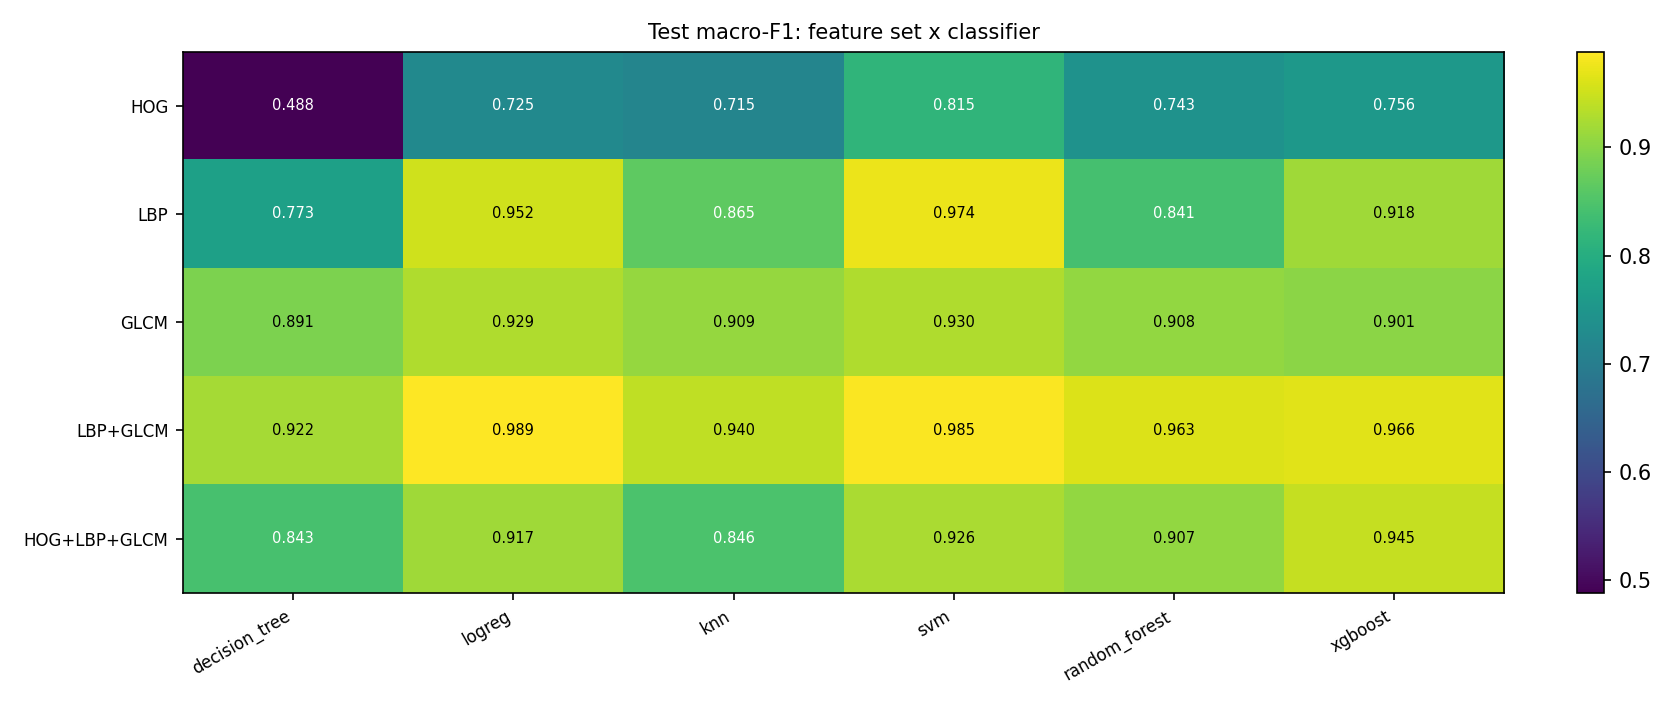

In [3]:
show(FIG / "classical" / "grid_test_macro_f1.png")

## Final model per classifier (feature set chosen by CV only)

In [4]:
fin = json.loads((RES / "classical" / "finals.json").read_text())
pd.DataFrame([{"model": v["display_name"], "cv_macro_f1": v["cv_macro_f1_mean"], "val_macro_f1": v["val_macro_f1"],
               "test_accuracy": v["accuracy"], "test_macro_f1": v["macro_f1"], "test_roc_auc": v["roc_auc_ovr_macro"],
               "latency_ms": v["latency_ms_per_image"], "best_params": v["best_params"]}
              for v in fin.values()]).round(4)

,model,cv_macro_f1,val_macro_f1,test_accuracy,test_macro_f1,test_roc_auc,latency_ms,best_params
0,LBP + GLCM + Decision Tree,0.8867,0.8621,0.9219,0.9216,0.9599,9.147,"{'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma..."
1,LBP + GLCM + Logistic Regression,0.9590,0.9449,0.9888,0.9887,0.9997,9.182,{'clf__C': 10.0}
2,LBP + GLCM + k-NN,0.9023,0.8821,0.9405,0.9401,0.9643,9.370,"{'clf__metric': 'manhattan', 'clf__n_neighbors..."
3,LBP + GLCM + SVM,0.9695,0.9340,0.9851,0.9850,0.9994,9.218,"{'clf__C': 100, 'clf__gamma': 0.00098039215686..."
4,HOG + LBP + GLCM + Random Forest,0.9228,0.8987,0.9071,0.9075,0.9947,22.840,"{'max_depth': None, 'max_features': 0.1, 'min_..."
5,HOG + LBP + GLCM + XGBoost,0.9282,0.9251,0.9442,0.9451,0.9977,14.275,"{'colsample_bytree': 0.3, 'learning_rate': 0.1..."


Findings:

* **Features matter more than classifiers.** With LBP + GLCM, a plain logistic regression (test
  macro-F1 0.989) and an RBF-SVM (0.985) lead; switching classifier moves the score by less than switching
  from HOG to texture features does.
* **The custom CNN (5 seeds, test macro-F1 0.988 +- 0.005) statistically ties the best classical
  model.** Each makes 3 test errors and they share one image, Sc_44: a very faint, wide scratch that
  all seven final models call inclusion.
* **Tree ensembles chose the HOG-containing feature set and make inclusion a catch-all class**
  (Random Forest misses a third of the scratches, predicting inclusion).

## Decision tree depth and overfitting

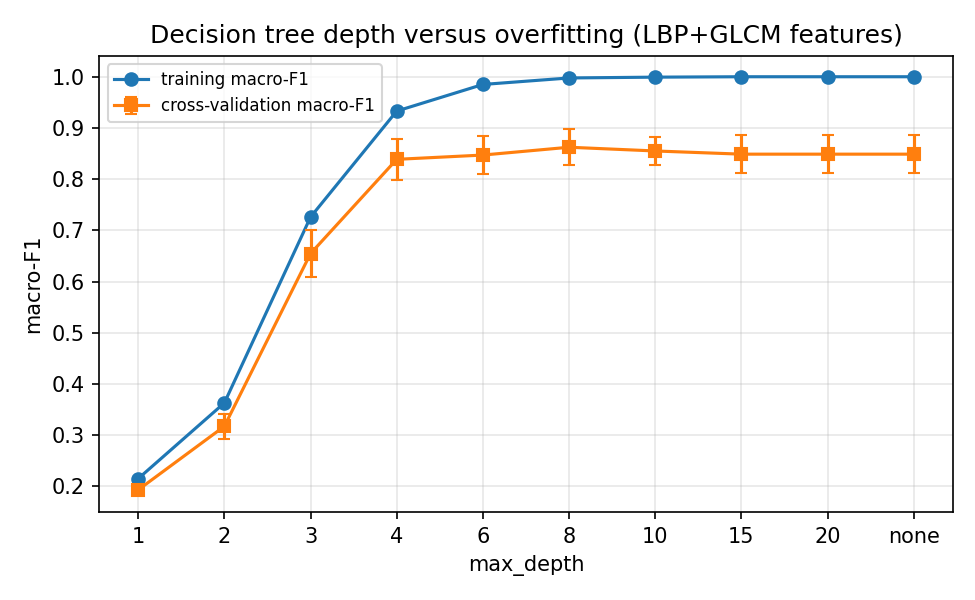

In [5]:
show(FIG / "classical" / "decision_tree_depth_curve.png")

Training macro-F1 is 0.998 at depth 8 and exactly 1.0 from depth 15, while cross-validation macro-F1
peaks at 0.862 (depth 8) and settles near 0.85:
the gap is the variance of a single tree. Bagging (Random Forest) and boosting (XGBoost) exist to close
exactly this gap.

## What the ensembles rely on

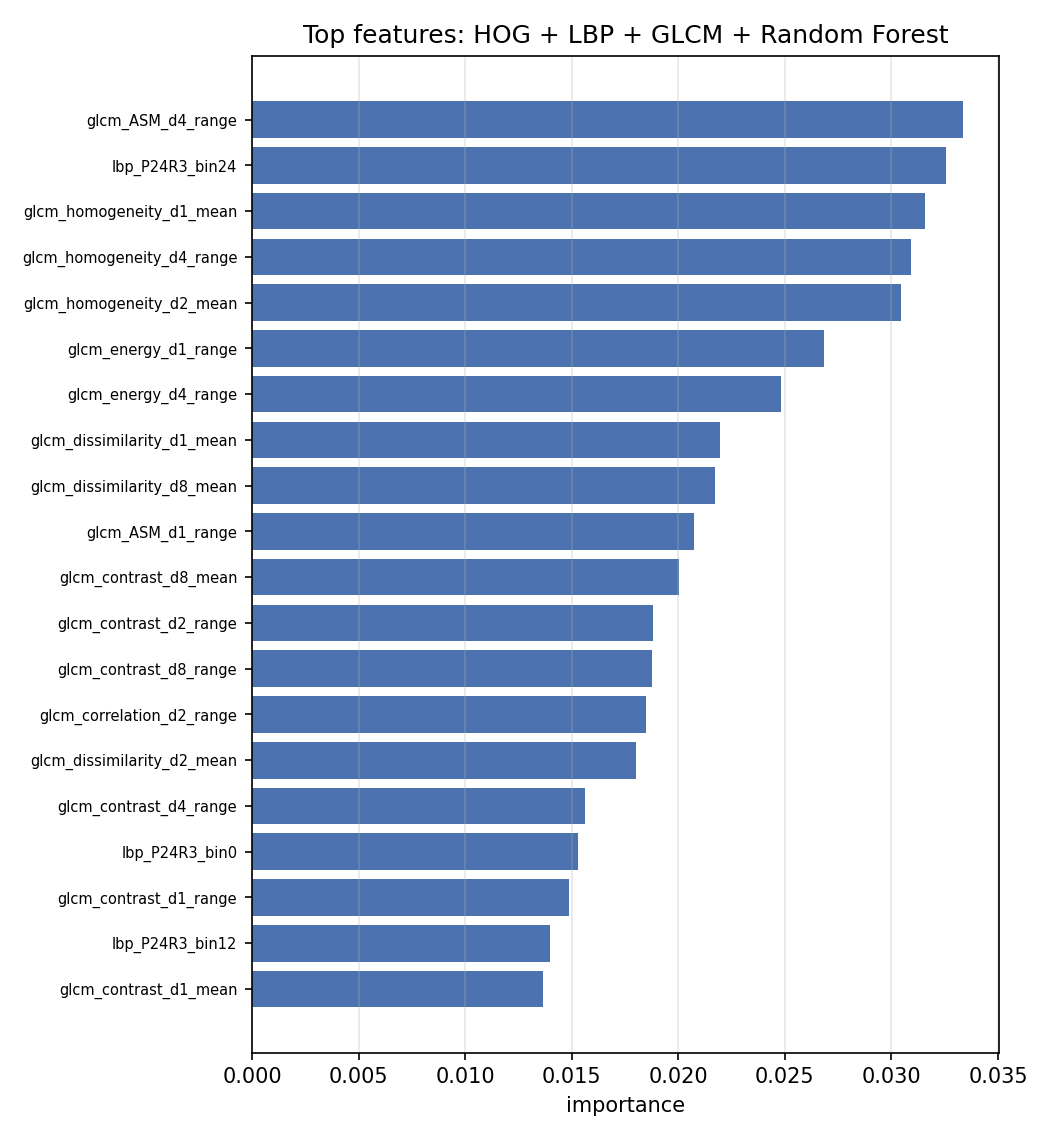

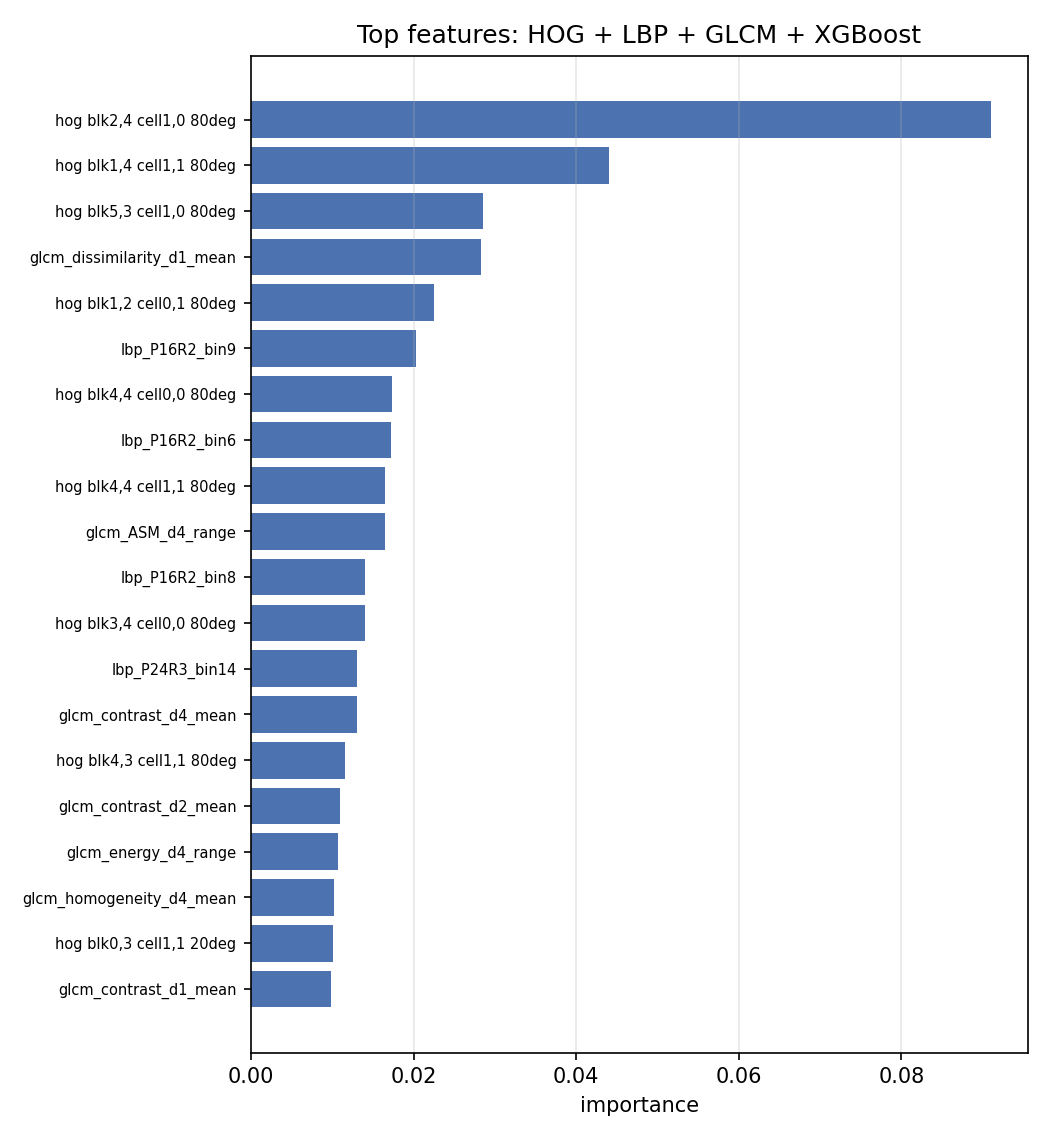

In [6]:
for p in sorted((FIG / "classical").glob("importances_*.png")):
    show(p)

## ROC and precision-recall curves (test split)

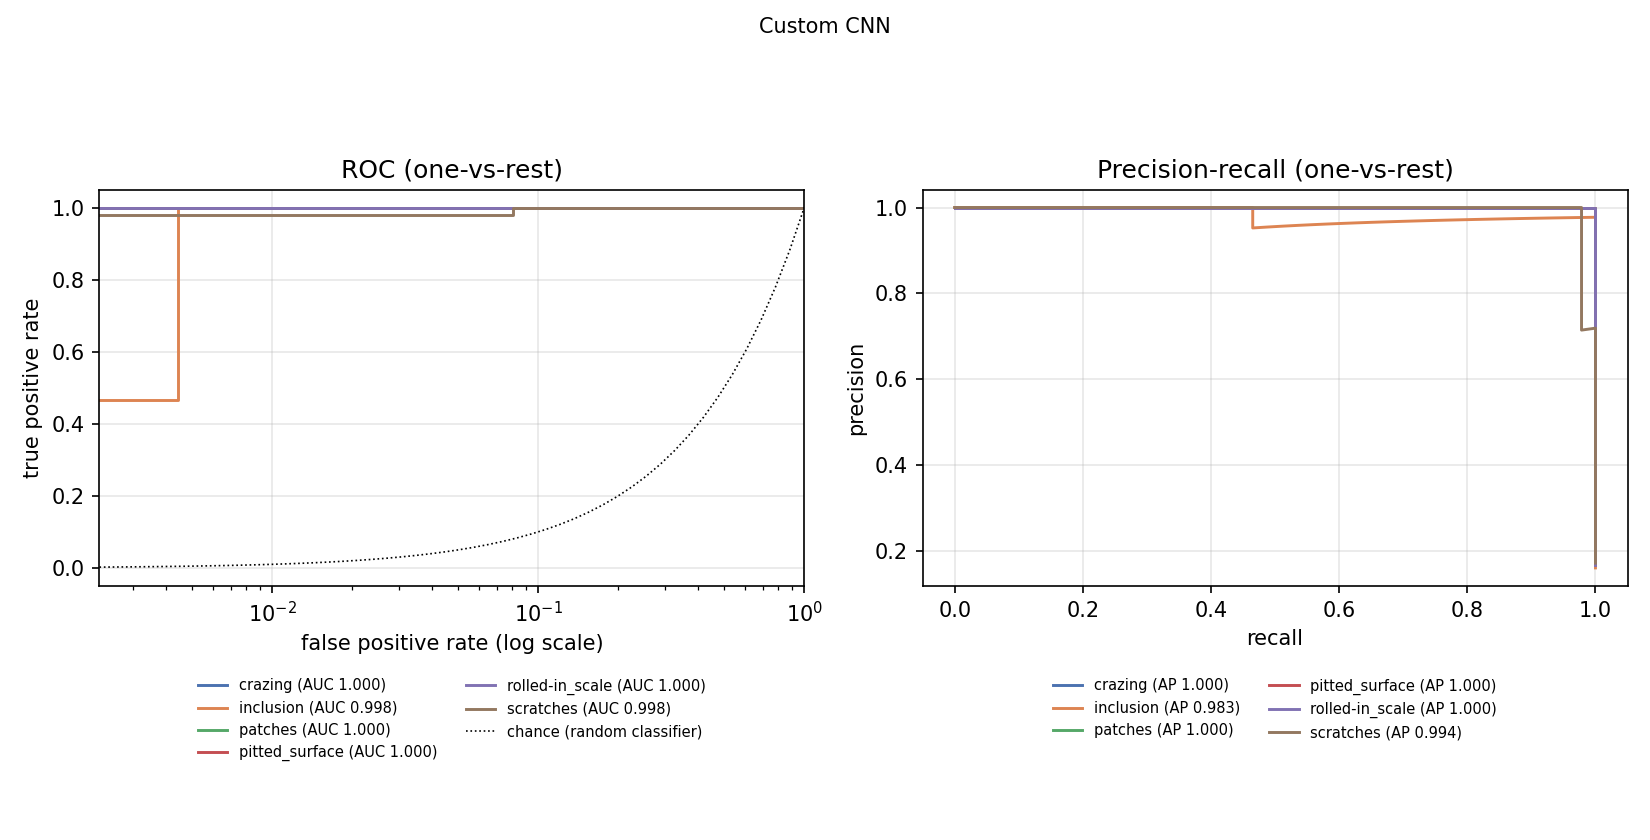

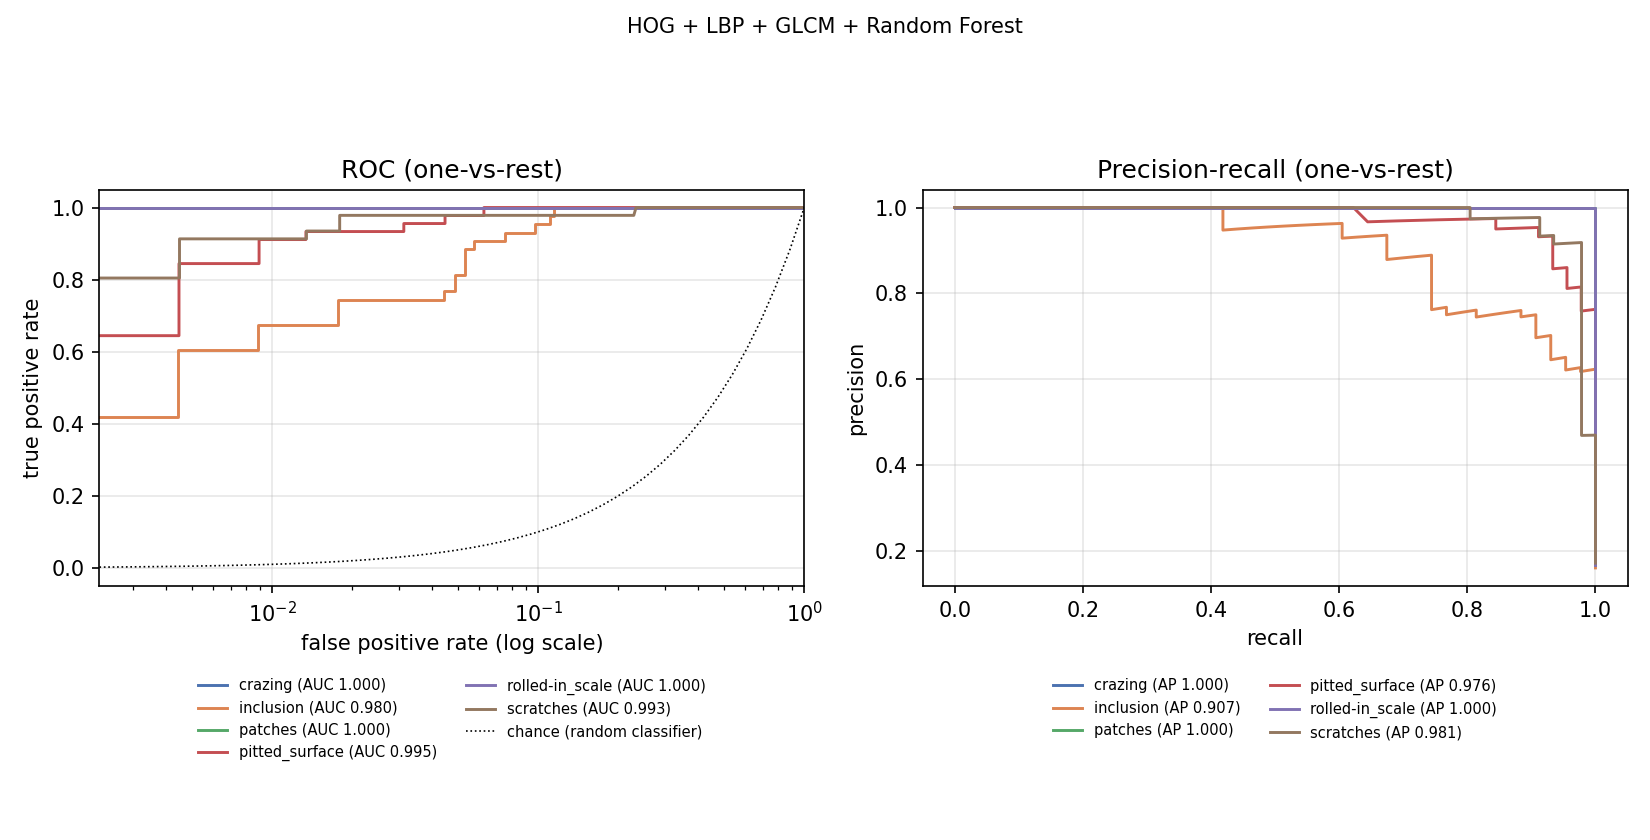

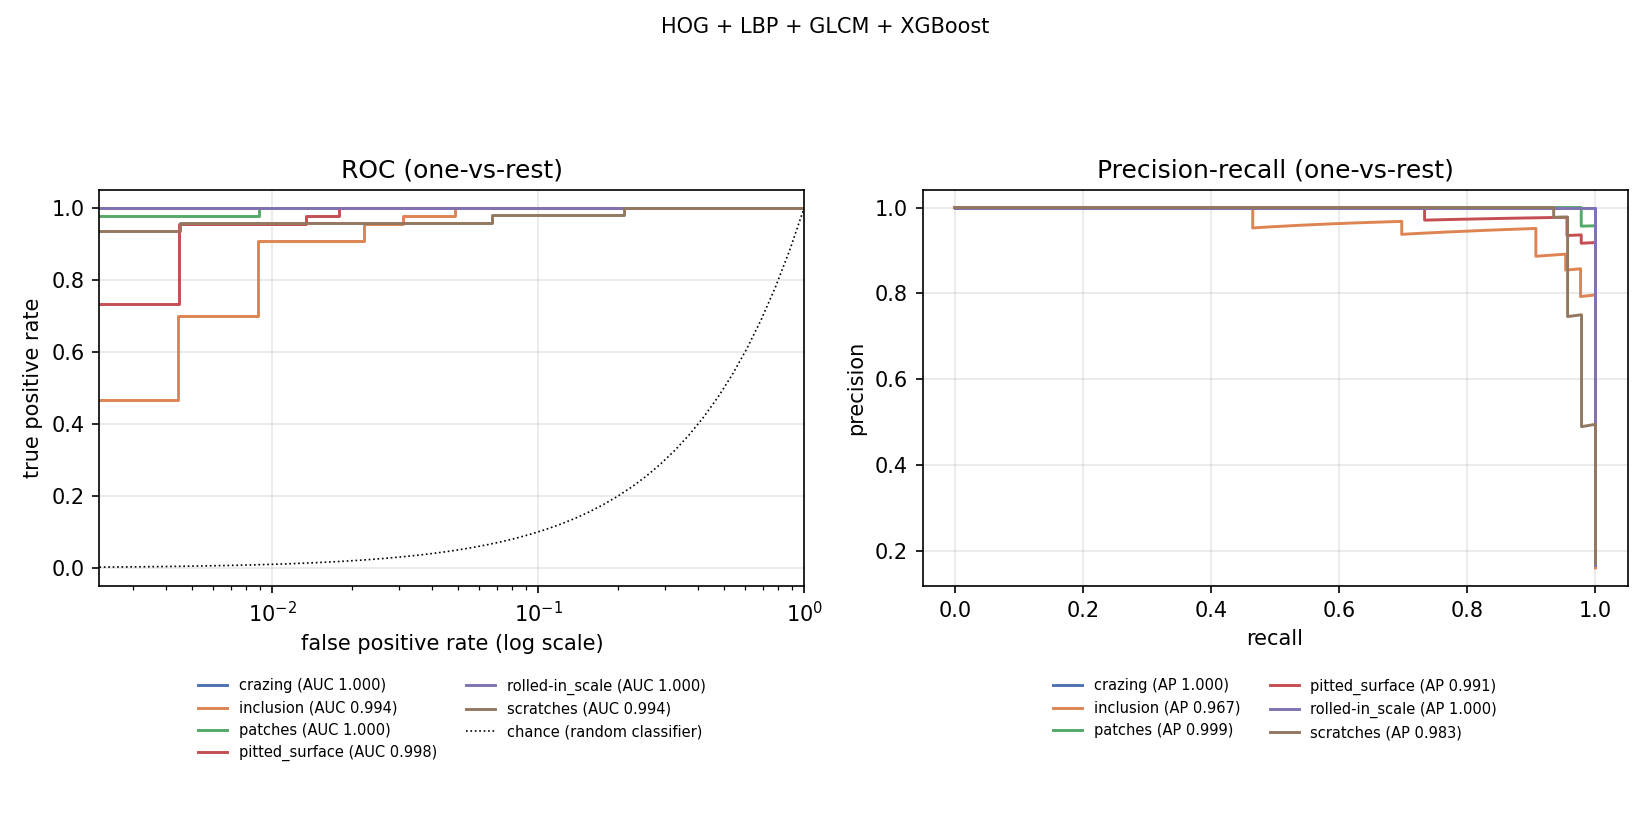

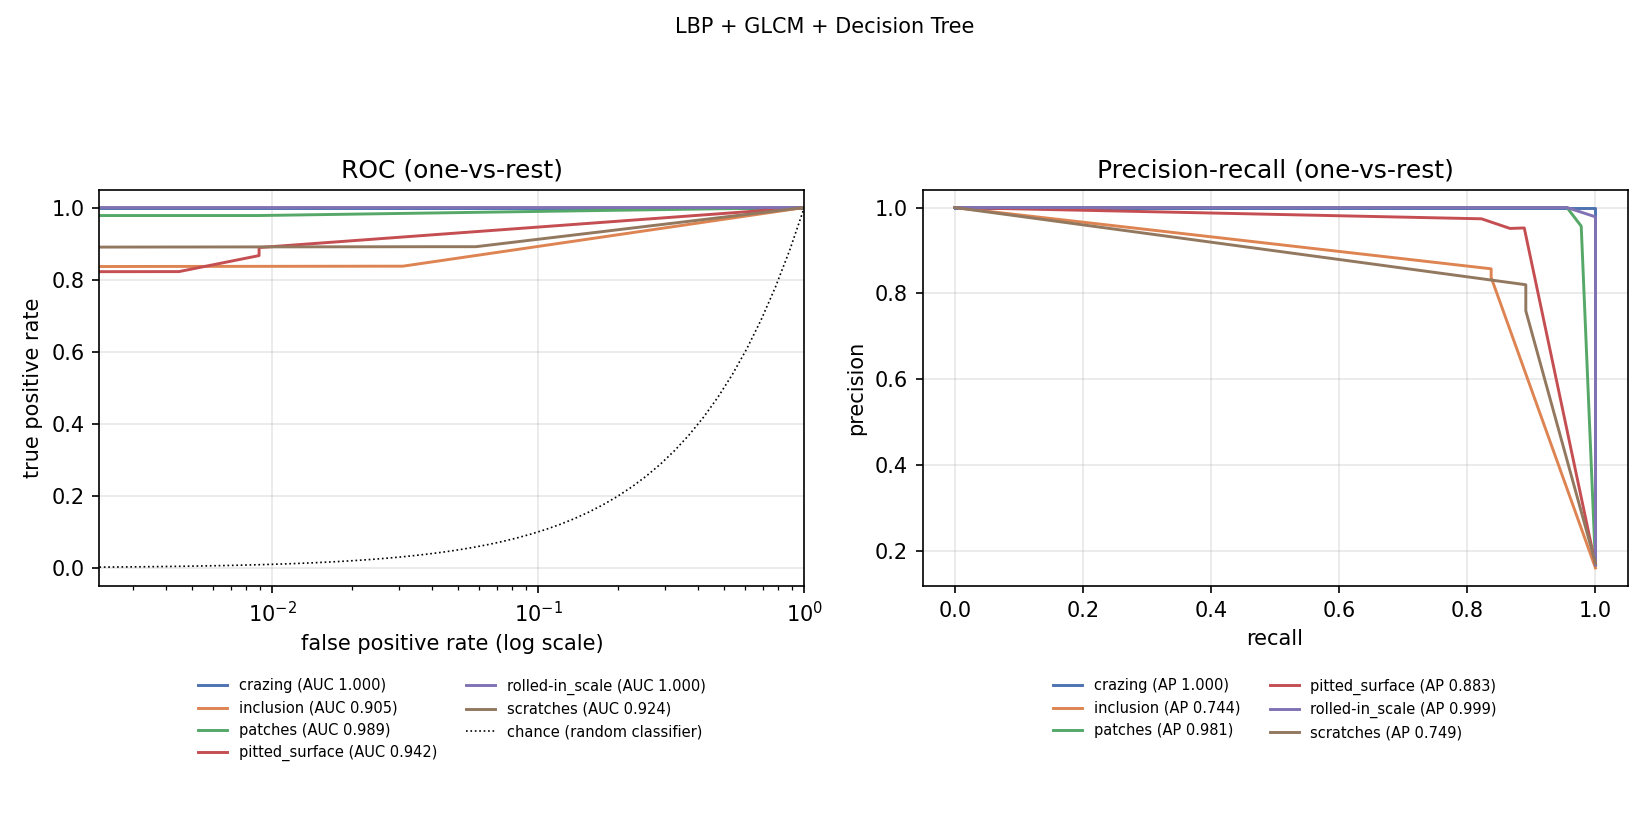

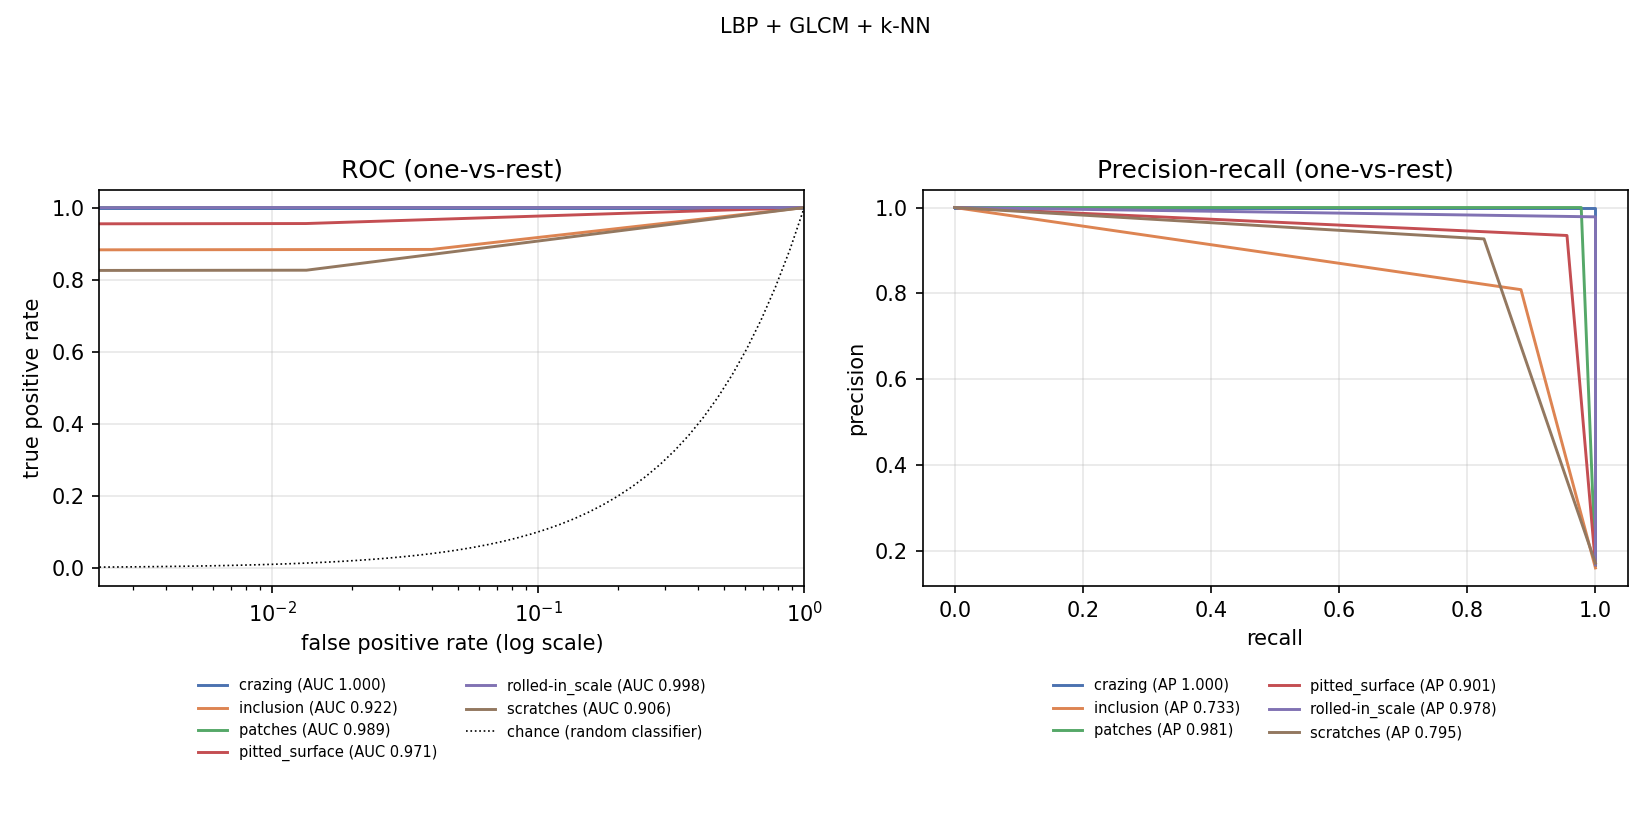

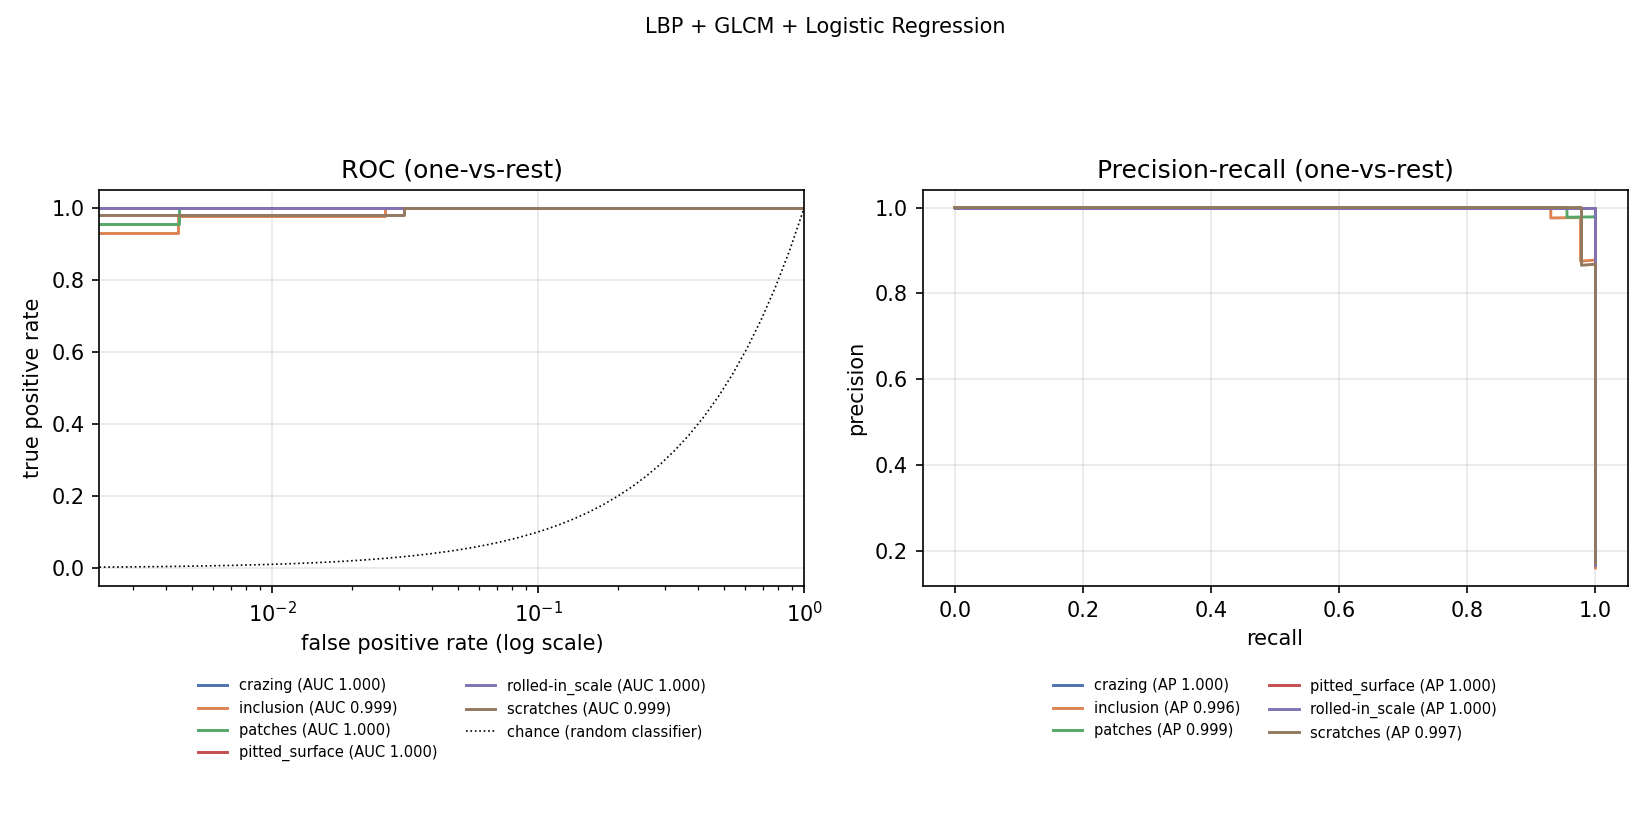

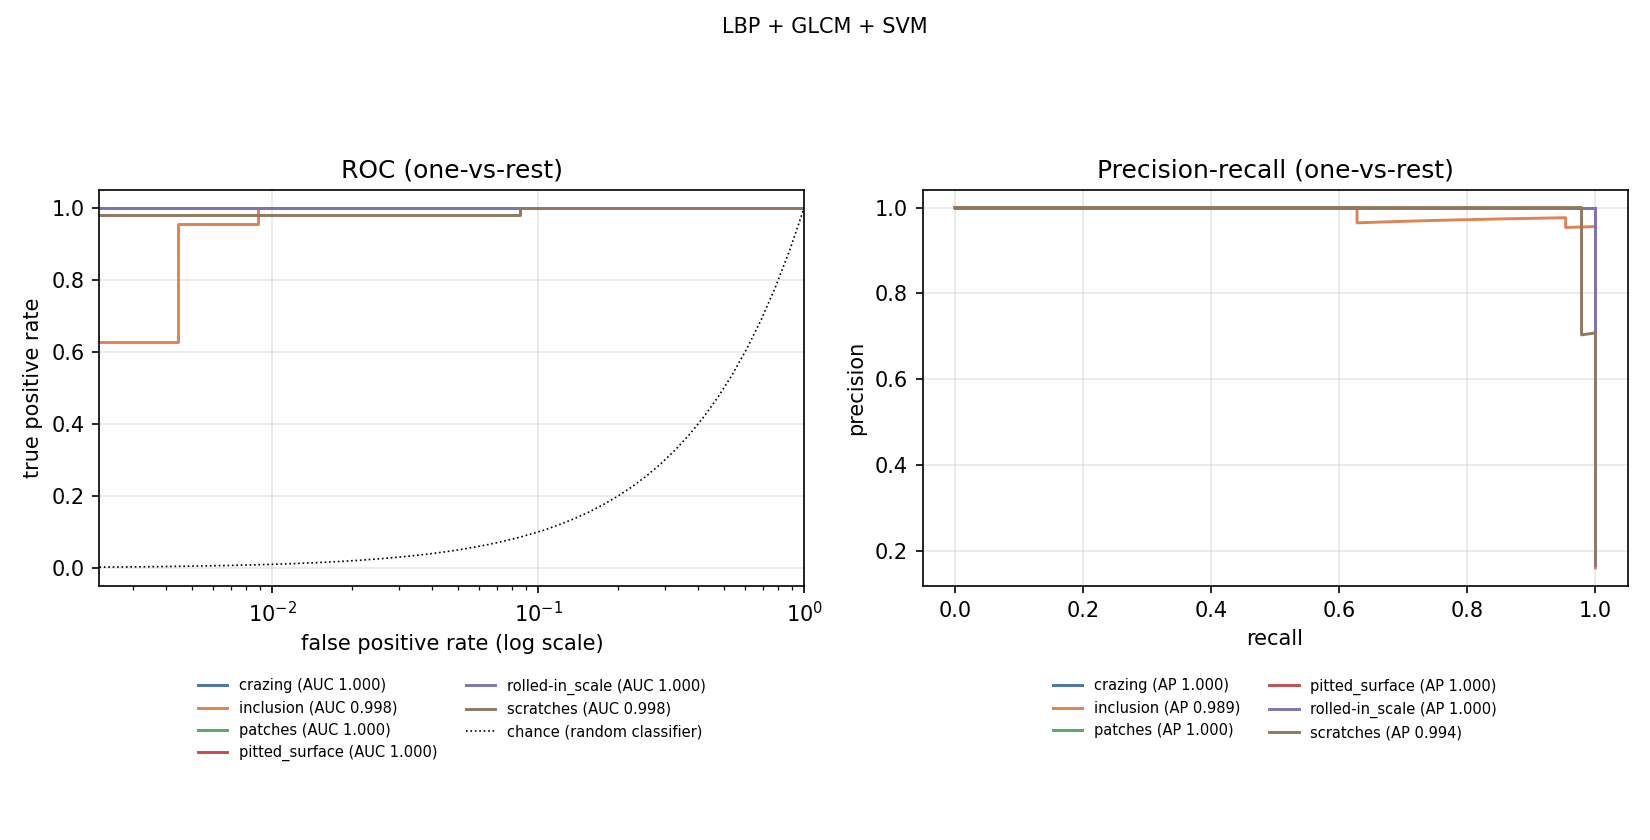

In [7]:
for p in sorted((FIG / "roc_pr").glob("*.png")):
    show(p)

## Ablations (cross-validation macro-F1, training split only)

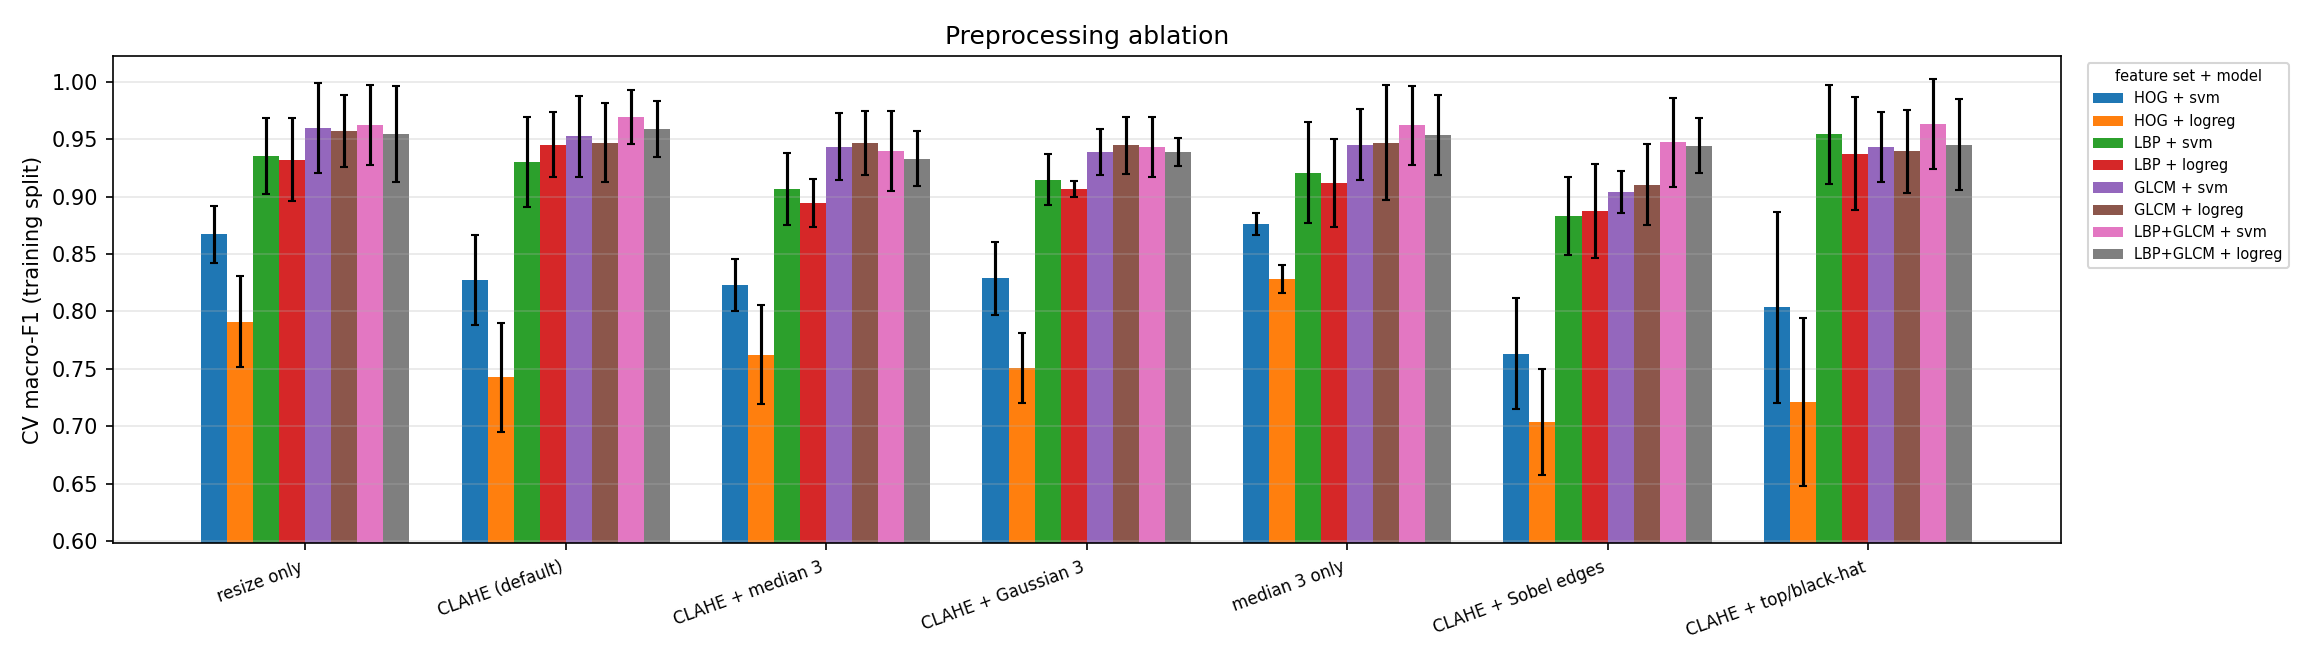

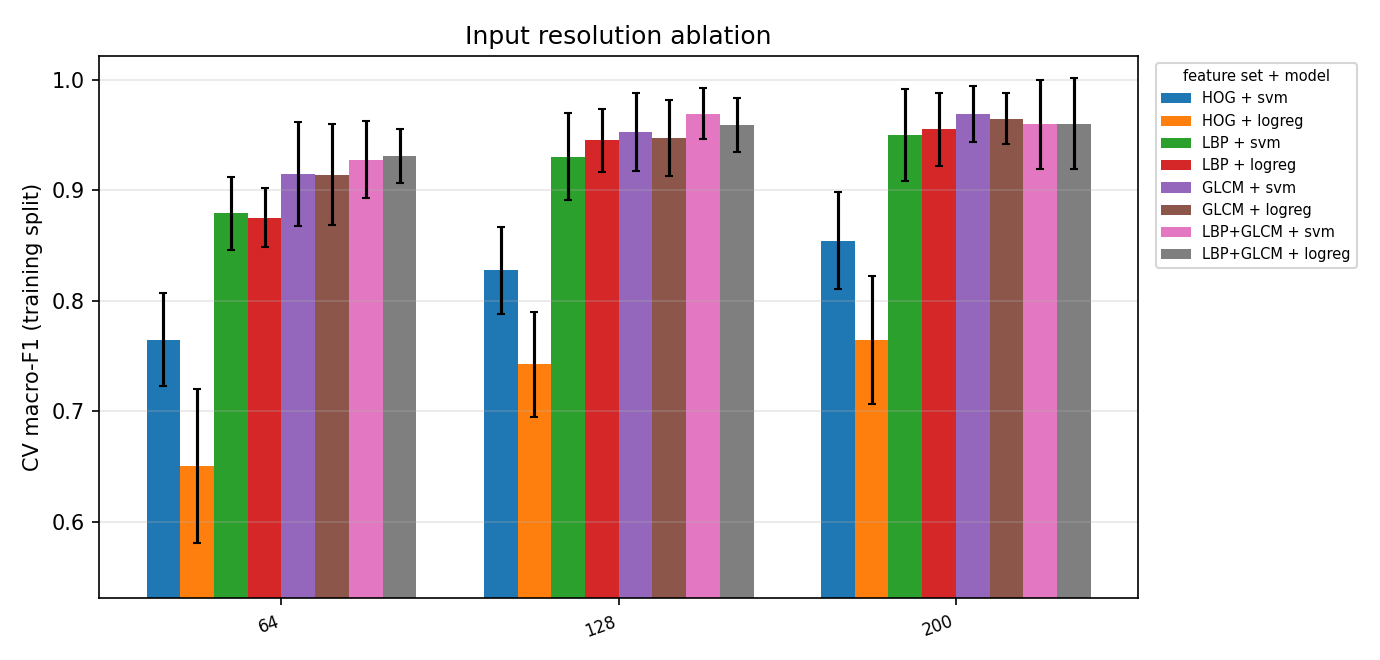

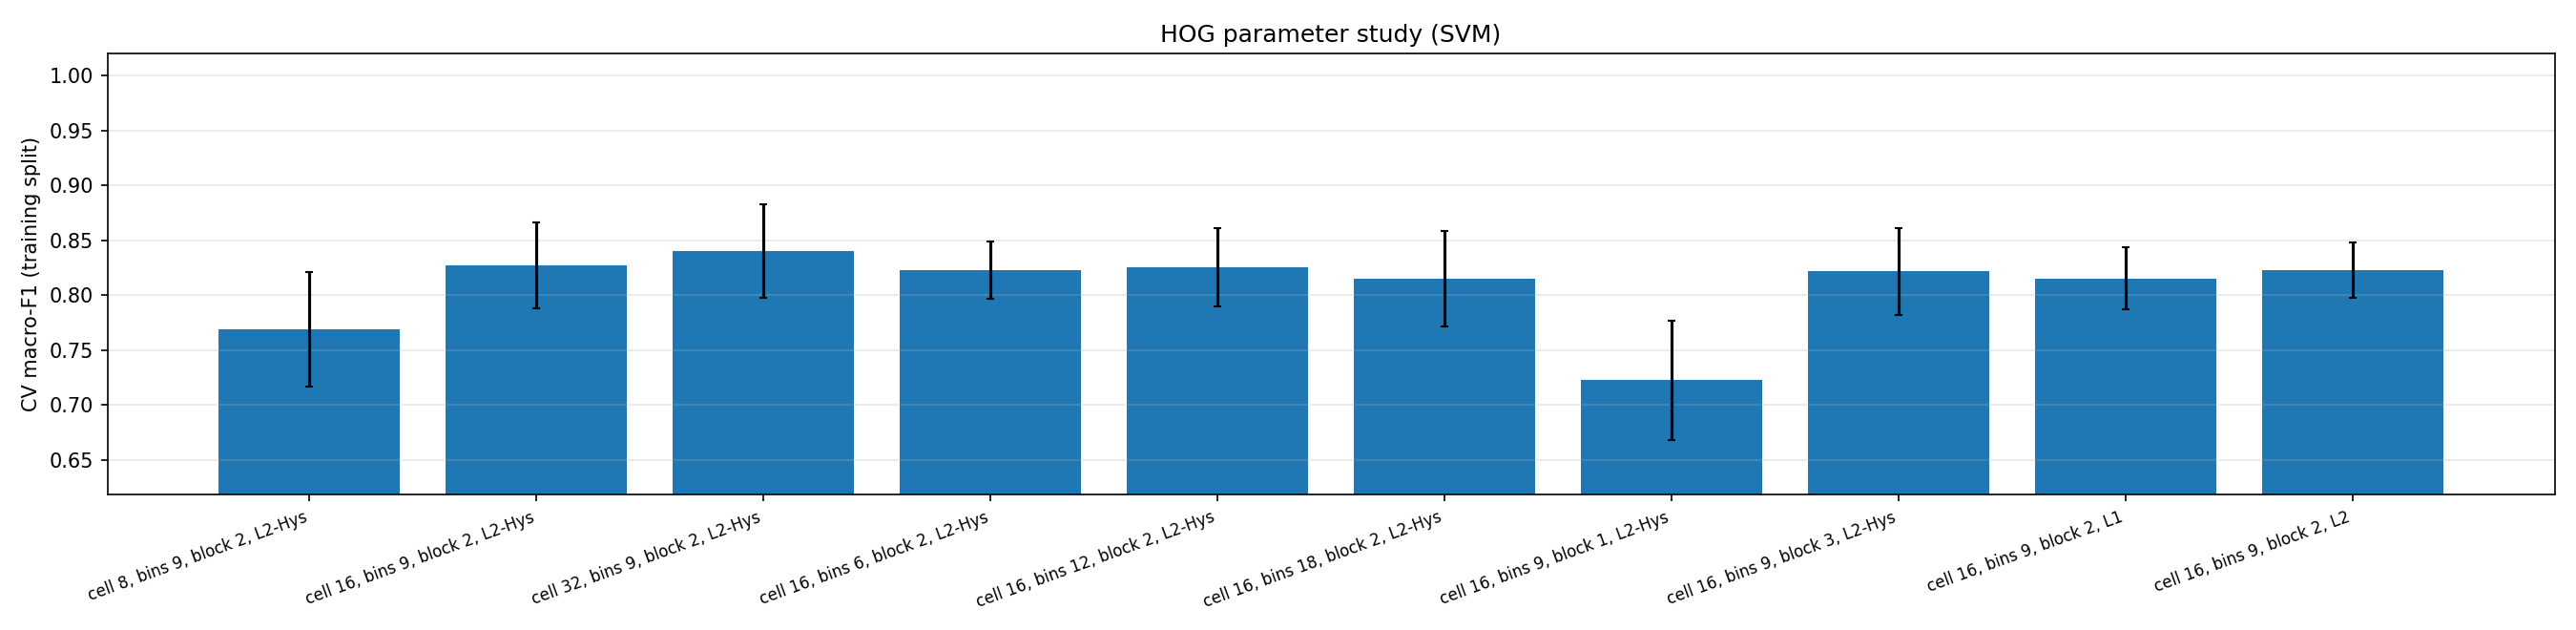

In [8]:
for k in ("preprocessing", "resolution", "hog"):
    show(FIG / "classical" / f"ablation_{k}.png")

Findings (cross-validation on the training split; the test split is not used here):

* **Denoising after CLAHE hurts LBP and LBP + GLCM** by about 0.02 to 0.05: blurring erases the
  micro-texture that LBP measures; GLCM is nearly unaffected (at most 0.014). **CLAHE hurts HOG**
  (about -0.04 to -0.05) by amplifying noise gradients. For the
  LBP + GLCM combination, CLAHE is best, but within noise of no enhancement at all.
* **Resolution:** 64 px costs every descriptor 0.03 to 0.09; single descriptors improve at native
  200 px, the combination ties between 128 and 200 px.
* **Edge and morphology enhanced input:** a Sobel edge map in place of the image hurts every
  descriptor (0.014 to 0.064 below CLAHE alone); top-hat/black-hat enhancement helps only LBP with an
  SVM (+0.024, within noise) and costs 0.006 to 0.024 elsewhere. These operations explain errors
  (notebook 01) but are not better model inputs.
* **HOG parameters:** block normalization is worth about +0.10 (block size 1 is much worse); coarse
  32 px cells are slightly better than 16 px; even the best HOG variant stays far below texture
  descriptors.

## Leakage study: random split versus group-aware split

In [9]:
ls = json.loads((RES / "leakage_study" / "leakage_study.json").read_text())
display(pd.DataFrame([{"split": k, "test images with a near-duplicate in train": v["test"]["leaked"],
                       "share": round(v["test"]["fraction"], 3)} for k, v in ls["leakage"].items()]))
pd.DataFrame(ls["models"]).round(4)

,split,test images with a near-duplicate in train,share
0,random (ignores near-duplicates),231,0.856
1,group-aware (this project),0,0.000


,split,model,test_macro_f1,test_macro_f1_std,seeds
0,random (ignores near-duplicates),lbp+glcm+logreg,0.9815,NaN,NaN
1,random (ignores near-duplicates),lbp+glcm+svm,0.9926,NaN,NaN
2,random (ignores near-duplicates),hog+svm,0.8730,NaN,NaN
3,random (ignores near-duplicates),custom_cnn,0.9988,0.0021,"[42, 43, 44]"
4,group-aware (this project),lbp+glcm+logreg,0.9887,NaN,NaN
5,group-aware (this project),lbp+glcm+svm,0.9850,NaN,NaN
6,group-aware (this project),hog+svm,0.8147,NaN,NaN
7,group-aware (this project),custom_cnn,0.9913,0.0043,"[42, 43, 44]"


Findings:

* With a plain random split, **85.6 percent of test images have a near-duplicate in the training set**;
  with the group-aware split, none do.
* **HOG + SVM is inflated most (+0.058 macro-F1):** HOG encodes where edges are, so a training crop that
  shares pixels with a test crop is nearly a memorized answer. The CNN reaches a perfect 1.000 on the
  random split for two of three seeds, the classic leakage signature; global texture histograms are
  affected least.
* The two splits have different test sets, so each gap also contains about +-0.01 of sampling noise; only
  the HOG gap is clearly larger than that.
* The group-aware rows reproduce Steps 2-2 and 2-4 exactly, which confirms the pipeline is deterministic.